In [17]:
purchases_by_department = (
    df[df["event_type"] == "purchase"]
    .groupby("department", observed=True)
    .size()
)

In [19]:
department_conversion = pd.DataFrame({
    "views": views_by_department,
    "purchases": purchases_by_department
}).fillna(0)

In [21]:
department_conversion["conversion_rate"] = (
    department_conversion["purchases"]
    / department_conversion["views"]
    * 100
)

In [23]:
department_conversion = (
    department_conversion[
        department_conversion["views"] >= 10000
    ]
    .sort_values(
        "conversion_rate",
        ascending=False
    )
    .head(10)
    .reset_index()
)

D:\Anaconda\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


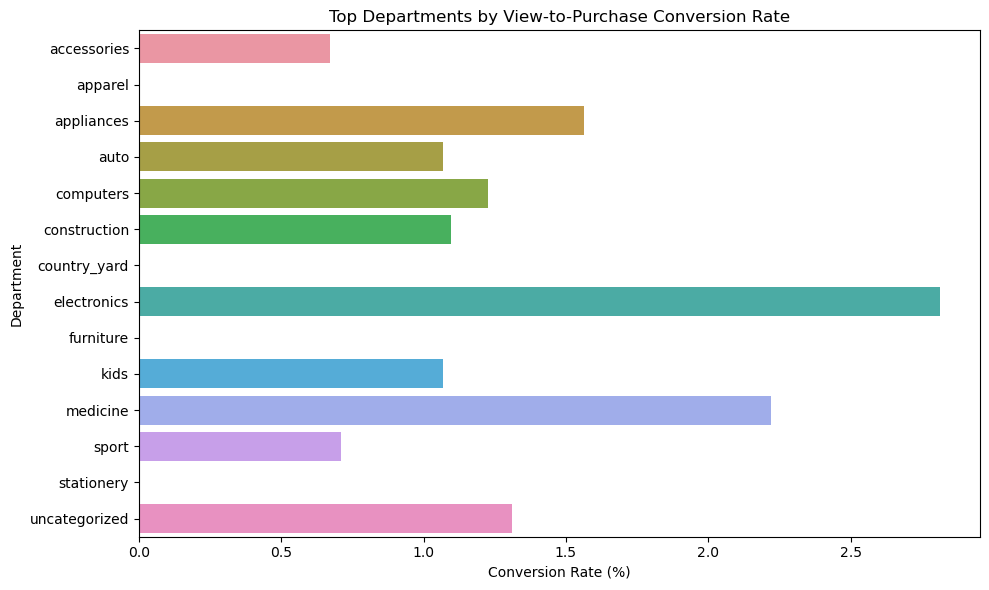

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=department_conversion,
    x="conversion_rate",
    y="department"
)

plt.title("Top Departments by View-to-Purchase Conversion Rate")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

In [27]:
top_categories = (
    df[
        (df["event_type"] == "purchase")
        & (df["category"] != "unspecified")
    ]
    .groupby("category", observed=True)
    .size()
    .sort_values(ascending=False)
    .head(15)
    .reset_index(name="purchases")
)

D:\Anaconda\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


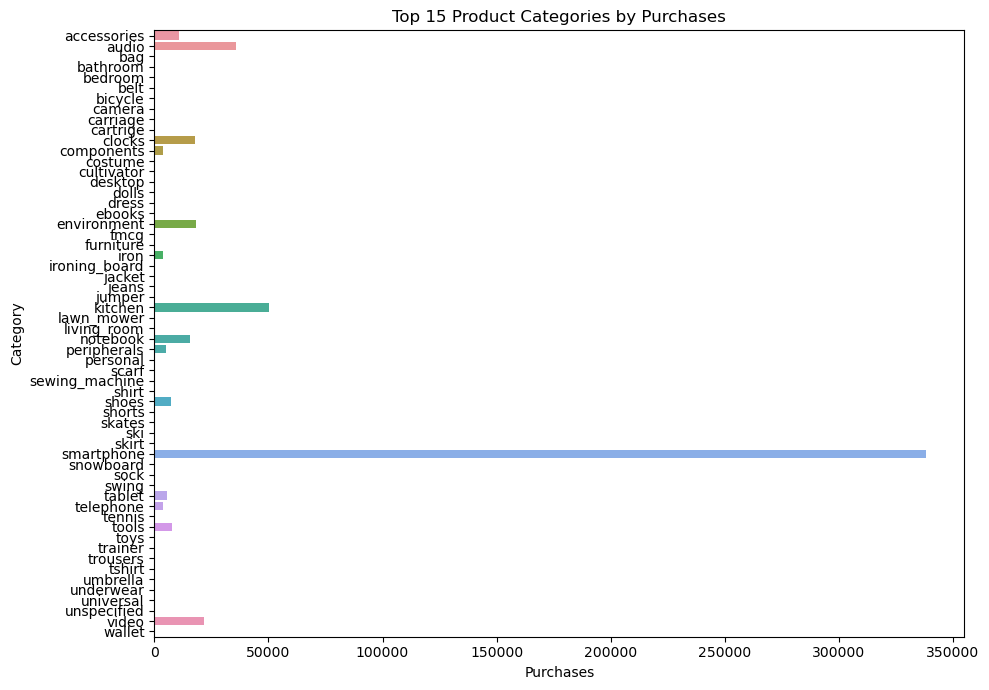

In [29]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_categories,
    x="purchases",
    y="category"
)

plt.title("Top 15 Product Categories by Purchases")
plt.xlabel("Purchases")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [31]:
top_brands = (
    df[
        (df["event_type"] == "purchase")
        & (df["brand"] != "unknown")
    ]
    .groupby("brand", observed=True)
    .size()
    .sort_values(ascending=False)
    .head(15)
    .reset_index(name="purchases")
)

In [34]:
hourly_activity = (
    df.groupby(
        ["hour", "event_type"],
        observed=True
    )
    .size()
    .reset_index(name="events")
)

D:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
D:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
D:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1057: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_data = data.groupby(


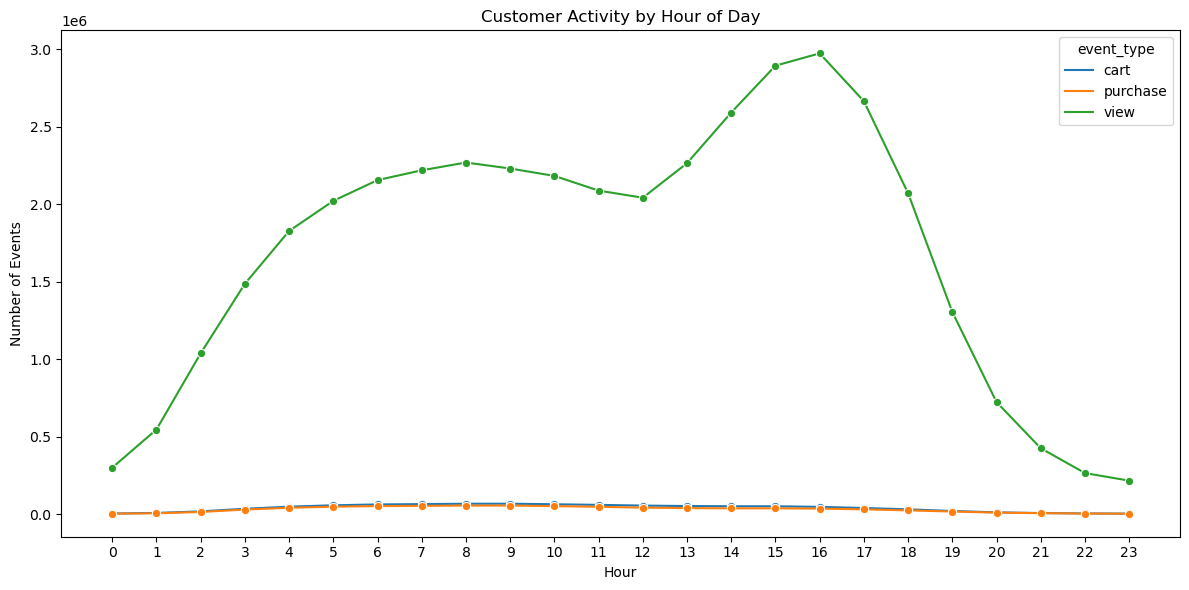

In [35]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_activity,
    x="hour",
    y="events",
    hue="event_type",
    marker="o"
)

plt.title("Customer Activity by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of Events")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

In [39]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

In [41]:
weekday_activity = (
    df.groupby(
        ["day_of_week", "event_type"],
        observed=True
    )
    .size()
    .reset_index(name="events")
)

D:\Anaconda\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


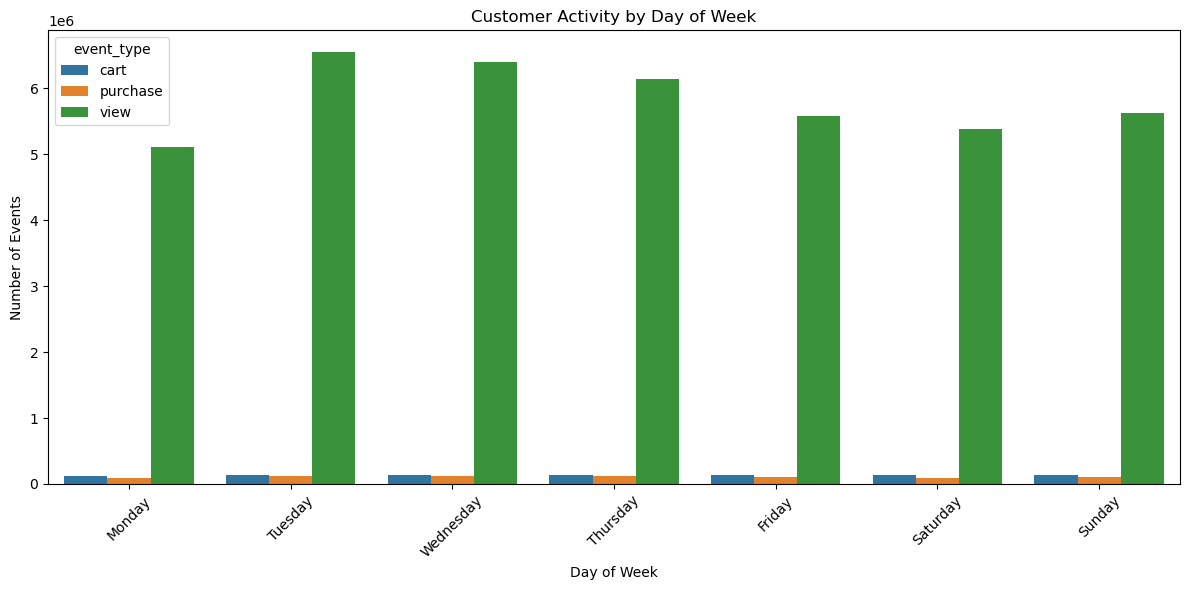

In [43]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=weekday_activity,
    x="day_of_week",
    y="events",
    hue="event_type",
    order=day_order
)

plt.title("Customer Activity by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
daily_events = (
    df.groupby(
        ["date", "weekend", "event_type"],
        observed=True
    )
    .size()
    .reset_index(name="events")
)

In [47]:
weekend_comparison = (
    daily_events.groupby(
        ["weekend", "event_type"],
        observed=True
    )["events"]
    .mean()
    .reset_index()
)

In [49]:
weekend_comparison["day_type"] = (
    weekend_comparison["weekend"]
    .map({
        False: "Weekday",
        True: "Weekend"
    })
)

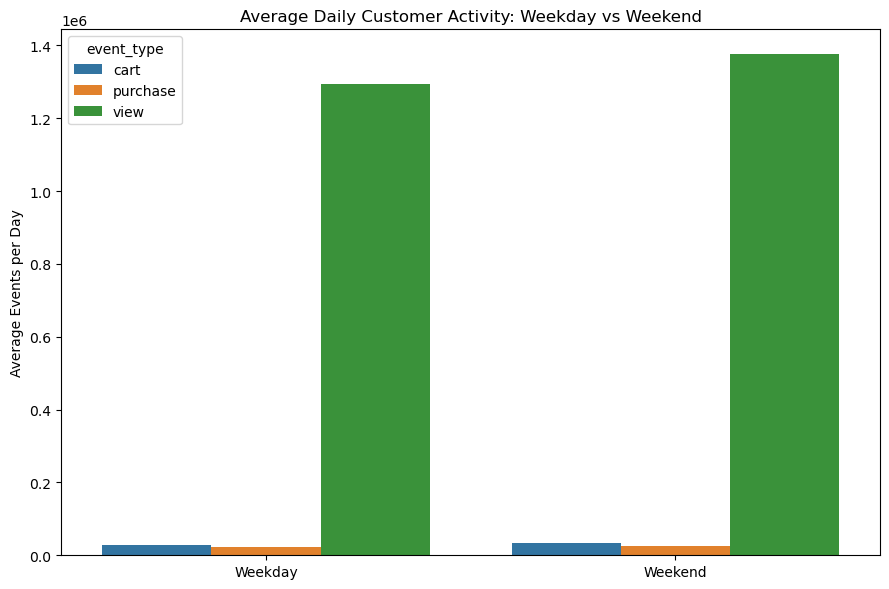

In [51]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=weekend_comparison,
    x="day_type",
    y="events",
    hue="event_type"
)

plt.title("Average Daily Customer Activity: Weekday vs Weekend")
plt.xlabel("")
plt.ylabel("Average Events per Day")
plt.tight_layout()
plt.show()

In [53]:
price_band_activity = (
    df.groupby(
        ["price_band", "event_type"],
        observed=True
    )
    .size()
    .reset_index(name="events")
)

D:\Anaconda\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


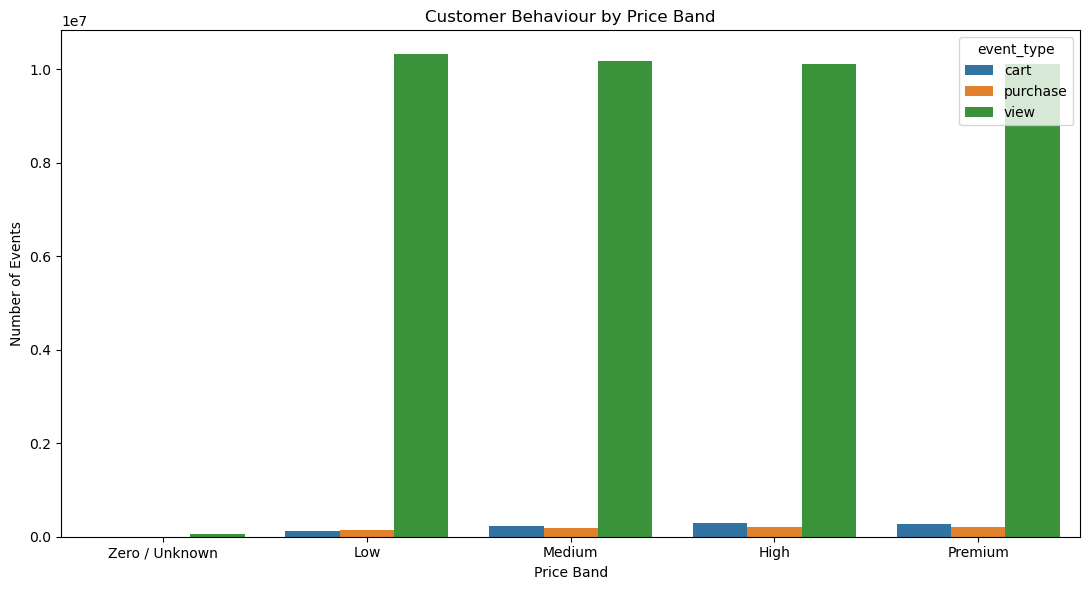

In [55]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=price_band_activity,
    x="price_band",
    y="events",
    hue="event_type"
)

plt.title("Customer Behaviour by Price Band")
plt.xlabel("Price Band")
plt.ylabel("Number of Events")
plt.tight_layout()
plt.show()

In [59]:
price_views = (
    df[df["event_type"] == "view"]
    .groupby("price_band", observed=True)
    .size()
)

price_purchases = (
    df[df["event_type"] == "purchase"]
    .groupby("price_band", observed=True)
    .size()
)

price_conversion = pd.DataFrame({
    "views": price_views,
    "purchases": price_purchases
}).fillna(0)

In [60]:
price_conversion["conversion_rate"] = (
    price_conversion["purchases"]
    / price_conversion["views"]
    * 100
)

price_conversion = price_conversion.reset_index()

D:\Anaconda\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


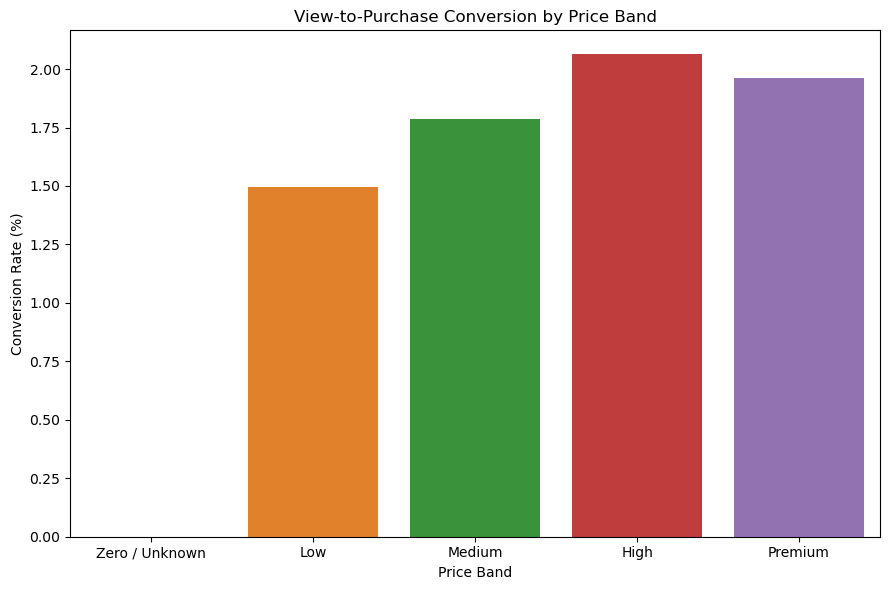

In [63]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=price_conversion,
    x="price_band",
    y="conversion_rate"
)

plt.title("View-to-Purchase Conversion by Price Band")
plt.xlabel("Price Band")
plt.ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.show()

In [65]:
daily_activity = (
    df.groupby(
        ["date", "event_type"],
        observed=True
    )
    .size()
    .reset_index(name="events")
)

D:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
D:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
D:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1057: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_data = data.groupby(


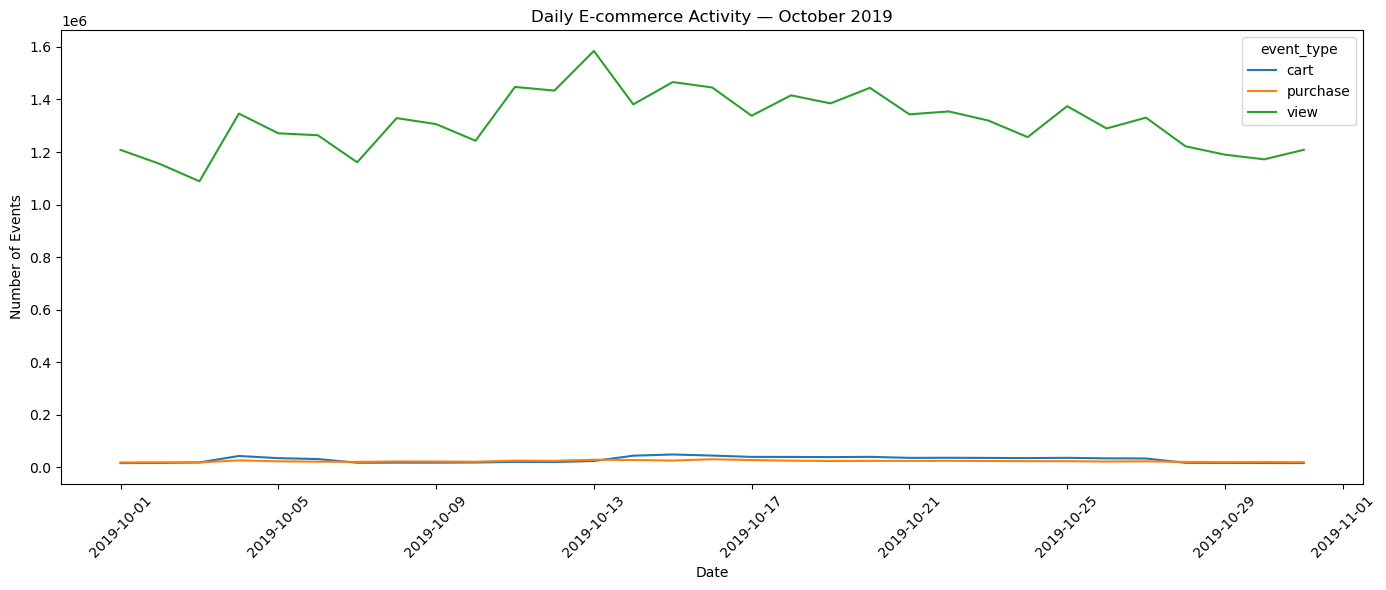

In [67]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_activity,
    x="date",
    y="events",
    hue="event_type"
)

plt.title("Daily E-commerce Activity — October 2019")
plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [69]:
department_comparison = (
    df[df["event_type"].isin(["view", "purchase"])]
    .groupby(
        ["department", "event_type"],
        observed=True
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

In [70]:
department_comparison["purchase_per_100_views"] = (
    department_comparison["purchase"]
    / department_comparison["view"]
    * 100
)

In [73]:
department_comparison.sort_values(
    "purchase_per_100_views",
    ascending=False
)

event_type,department,purchase,view,purchase_per_100_views
7,electronics,423028,15038390,2.812987
10,medicine,310,13974,2.218406
12,stationery,134,7380,1.815718
2,appliances,74996,4799936,1.562437
13,uncategorized,173425,13236458,1.310207
4,computers,27855,2268928,1.227672
5,construction,7801,712690,1.094585
9,kids,5482,512485,1.069690
3,auto,10620,993428,1.069026
11,sport,1236,174324,0.709025


In [88]:
plt.savefig(
    "../images/hourly_activity.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

D:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
D:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
D:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1057: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_data = data.groupby(


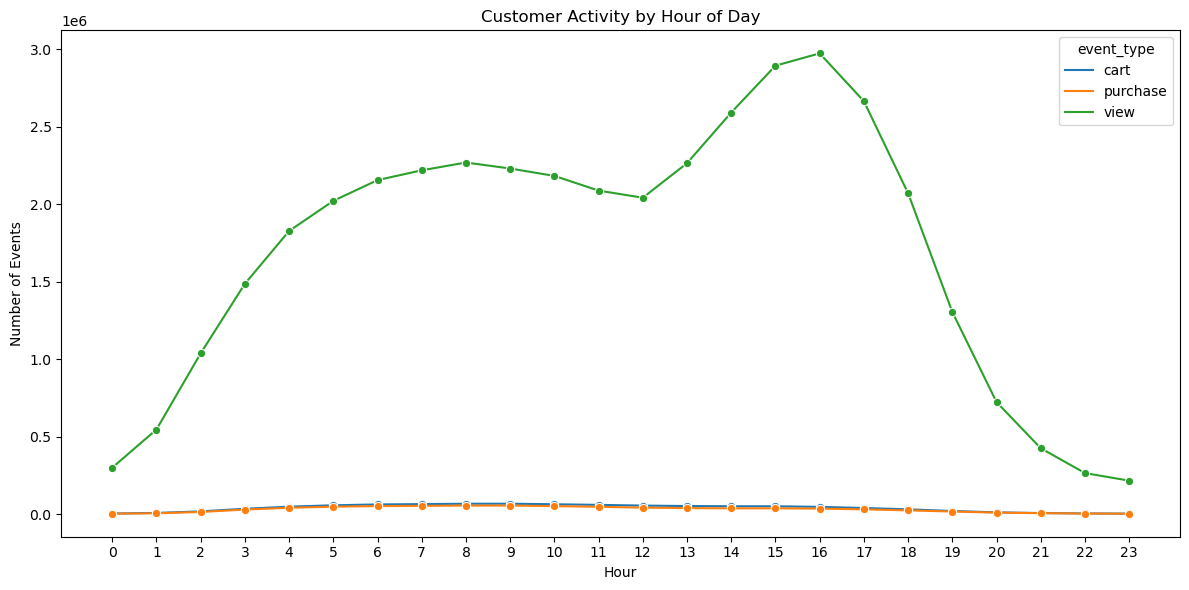

In [90]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_activity,
    x="hour",
    y="events",
    hue="event_type",
    marker="o"
)

plt.title("Customer Activity by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of Events")
plt.xticks(range(24))
plt.tight_layout()

plt.savefig(
    "../images/hourly_activity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

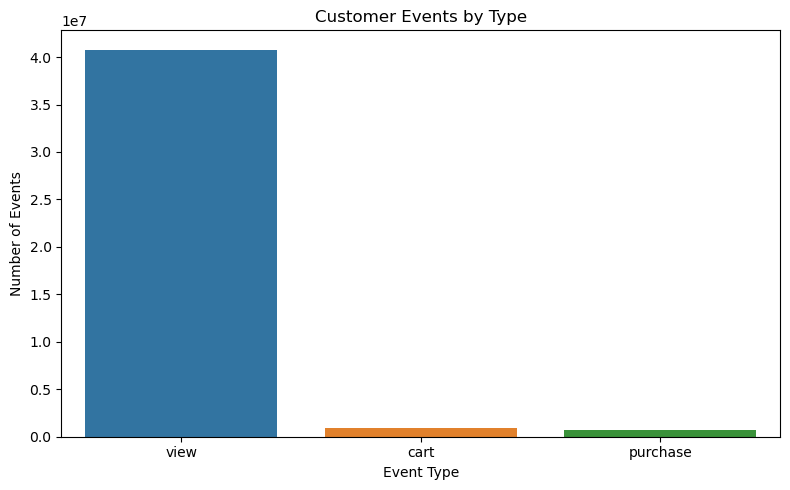

In [92]:
event_counts = (
    df["event_type"]
    .value_counts()
    .reindex(["view", "cart", "purchase"])
    .reset_index()
)

event_counts.columns = ["event_type", "count"]

plt.figure(figsize=(8, 5))

sns.barplot(
    data=event_counts,
    x="event_type",
    y="count"
)

plt.title("Customer Events by Type")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.tight_layout()

plt.savefig(
    "../images/01_event_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

D:\Anaconda\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


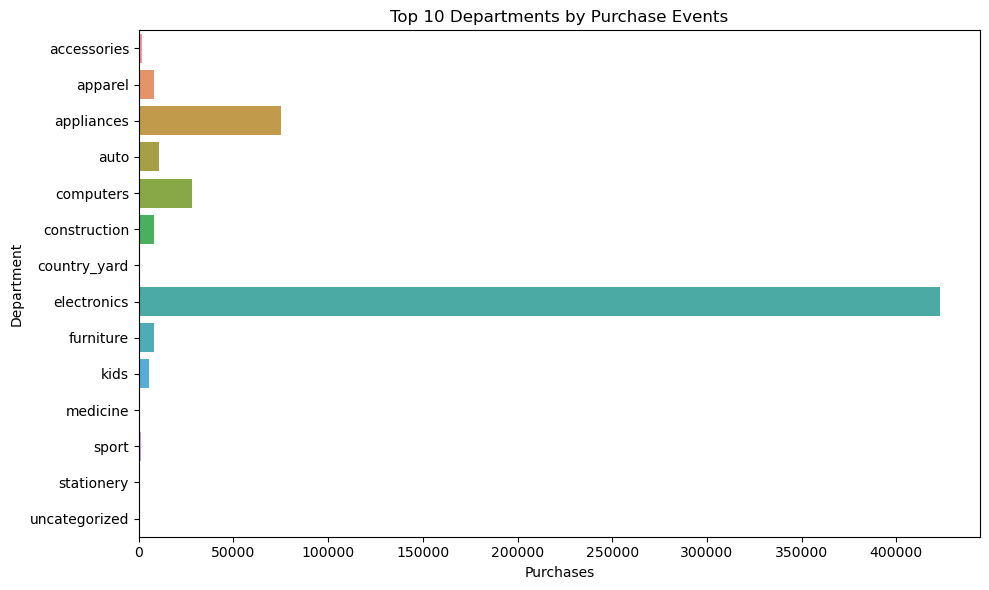

In [94]:
department_purchases = (
    df[
        (df["event_type"] == "purchase")
        & (df["department"] != "uncategorized")
    ]
    .groupby("department", observed=True)
    .size()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="purchases")
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=department_purchases,
    x="purchases",
    y="department"
)

plt.title("Top 10 Departments by Purchase Events")
plt.xlabel("Purchases")
plt.ylabel("Department")
plt.tight_layout()

plt.savefig(
    "../images/02_department_purchases.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

D:\Anaconda\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


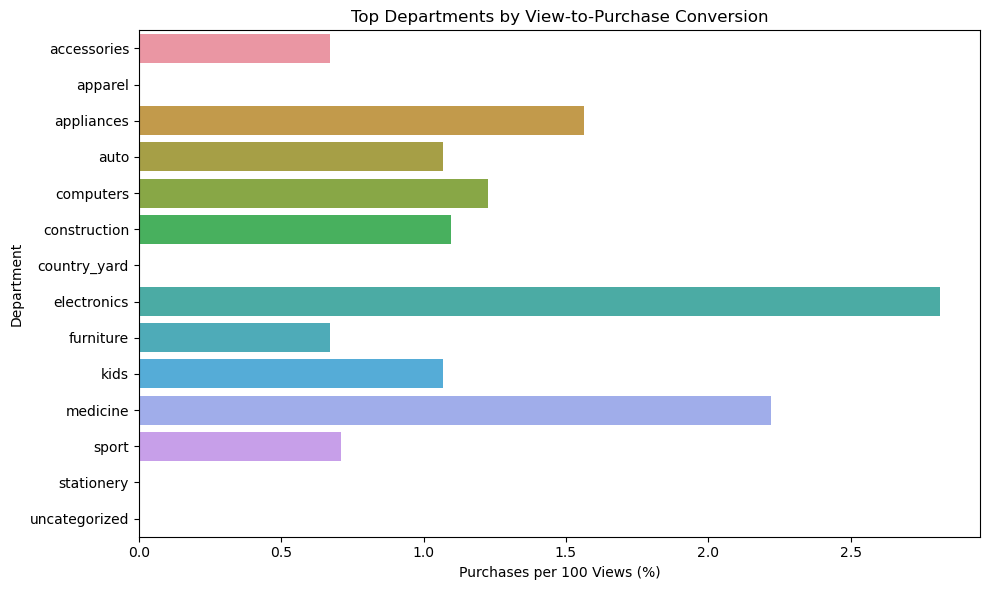

In [96]:
department_views = (
    df[df["event_type"] == "view"]
    .groupby("department", observed=True)
    .size()
)

department_purchases_all = (
    df[df["event_type"] == "purchase"]
    .groupby("department", observed=True)
    .size()
)

department_conversion = pd.DataFrame({
    "views": department_views,
    "purchases": department_purchases_all
}).fillna(0)

department_conversion["conversion_rate"] = (
    department_conversion["purchases"]
    / department_conversion["views"]
    * 100
)

department_conversion = (
    department_conversion[
        (department_conversion["views"] >= 10000)
        & (department_conversion.index != "uncategorized")
    ]
    .sort_values("conversion_rate", ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=department_conversion,
    x="conversion_rate",
    y="department"
)

plt.title("Top Departments by View-to-Purchase Conversion")
plt.xlabel("Purchases per 100 Views (%)")
plt.ylabel("Department")
plt.tight_layout()

plt.savefig(
    "../images/03_department_conversion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

D:\Anaconda\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


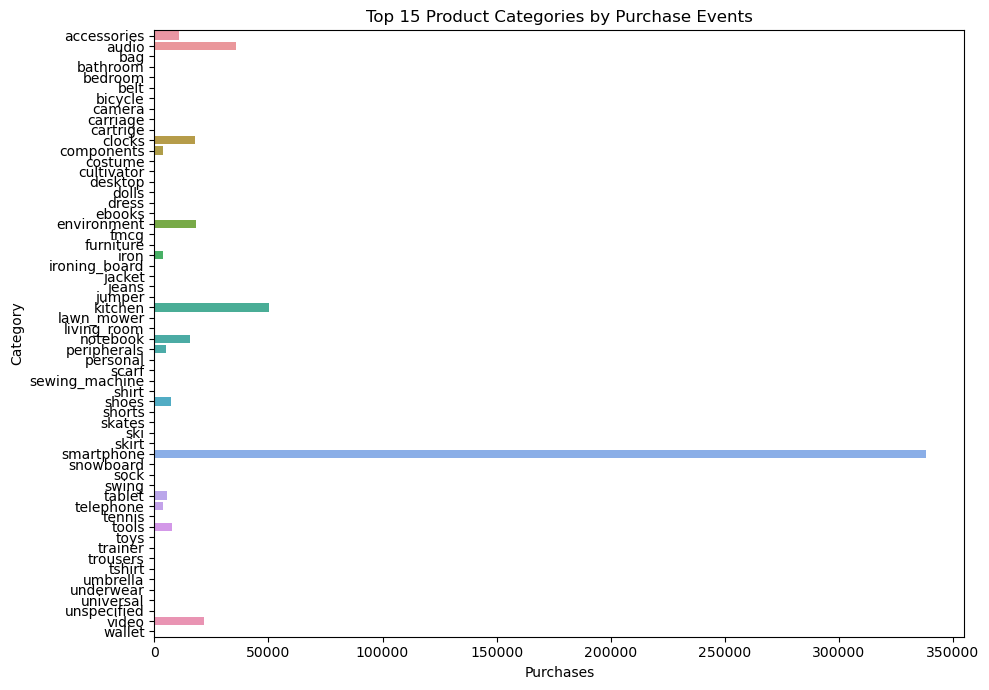

In [98]:
category_purchases = (
    df[
        (df["event_type"] == "purchase")
        & (df["category"] != "unspecified")
    ]
    .groupby("category", observed=True)
    .size()
    .sort_values(ascending=False)
    .head(15)
    .reset_index(name="purchases")
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=category_purchases,
    x="purchases",
    y="category"
)

plt.title("Top 15 Product Categories by Purchase Events")
plt.xlabel("Purchases")
plt.ylabel("Category")
plt.tight_layout()

plt.savefig(
    "../images/04_category_purchases.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

D:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
D:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
D:\Anaconda\Lib\site-packages\seaborn\_oldcore.py:1057: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_data = data.groupby(


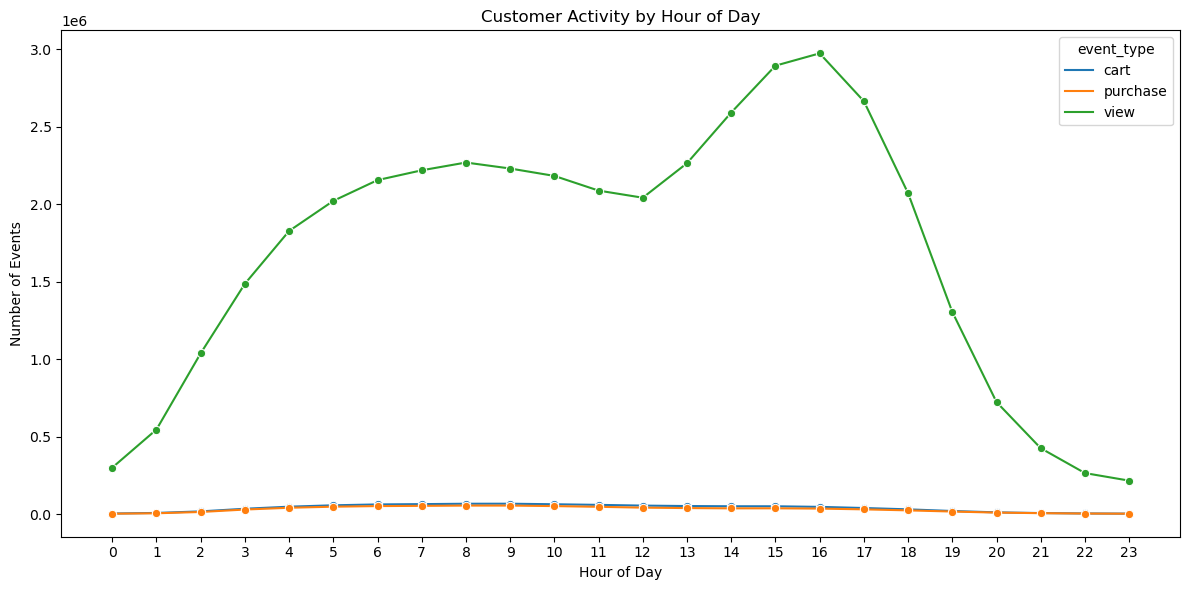

In [100]:
hourly_activity = (
    df.groupby(
        ["hour", "event_type"],
        observed=True
    )
    .size()
    .reset_index(name="events")
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_activity,
    x="hour",
    y="events",
    hue="event_type",
    marker="o"
)

plt.title("Customer Activity by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Events")
plt.xticks(range(24))
plt.tight_layout()

plt.savefig(
    "../images/05_hourly_activity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

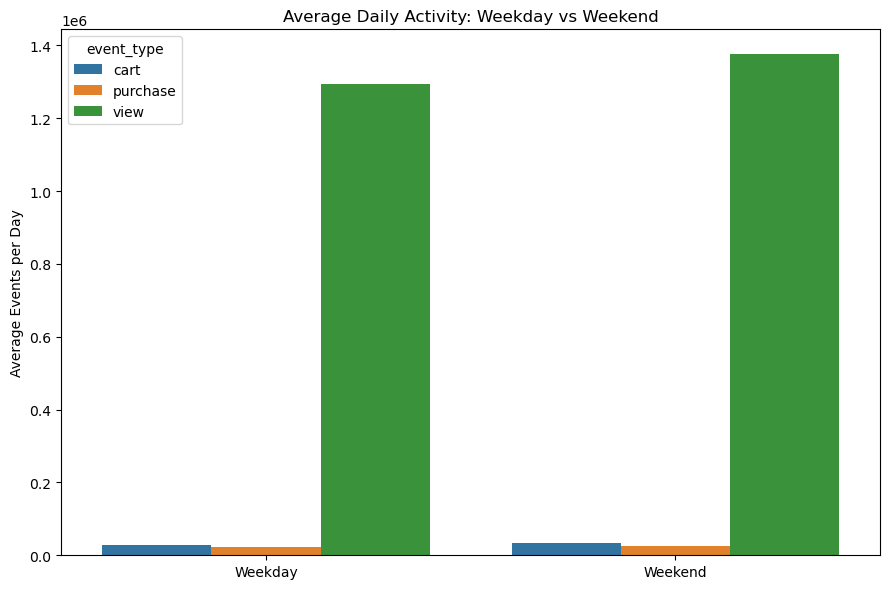

In [102]:
daily_events = (
    df.groupby(
        ["date", "weekend", "event_type"],
        observed=True
    )
    .size()
    .reset_index(name="events")
)

weekend_activity = (
    daily_events.groupby(
        ["weekend", "event_type"],
        observed=True
    )["events"]
    .mean()
    .reset_index()
)

weekend_activity["day_type"] = (
    weekend_activity["weekend"]
    .map({
        False: "Weekday",
        True: "Weekend"
    })
)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=weekend_activity,
    x="day_type",
    y="events",
    hue="event_type"
)

plt.title("Average Daily Activity: Weekday vs Weekend")
plt.xlabel("")
plt.ylabel("Average Events per Day")
plt.tight_layout()

plt.savefig(
    "../images/06_weekday_weekend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

D:\Anaconda\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


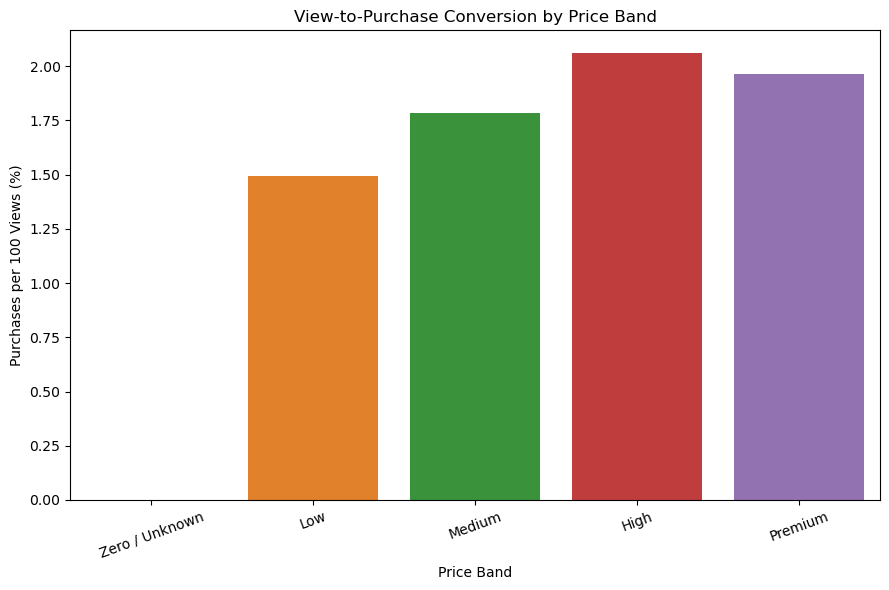

In [104]:
price_views = (
    df[df["event_type"] == "view"]
    .groupby("price_band", observed=True)
    .size()
)

price_purchases = (
    df[df["event_type"] == "purchase"]
    .groupby("price_band", observed=True)
    .size()
)

price_conversion = pd.DataFrame({
    "views": price_views,
    "purchases": price_purchases
}).fillna(0)

price_conversion["conversion_rate"] = (
    price_conversion["purchases"]
    / price_conversion["views"]
    * 100
)

price_conversion = price_conversion.reset_index()

plt.figure(figsize=(9, 6))

sns.barplot(
    data=price_conversion,
    x="price_band",
    y="conversion_rate"
)

plt.title("View-to-Purchase Conversion by Price Band")
plt.xlabel("Price Band")
plt.ylabel("Purchases per 100 Views (%)")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    "../images/07_price_band_conversion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [106]:
os.listdir("../images")

['.ipynb_checkpoints',
 '01_event_distribution.png',
 '02_department_purchases.png',
 '03_department_conversion.png',
 '04_category_purchases.png',
 '05_hourly_activity.png',
 '06_weekday_weekend.png',
 '07_price_band_conversion.png',
 'hourly_activity.png']

In [108]:
# 1. Event distribution
event_counts

,event_type,count
0,view,40779399
1,cart,926516
2,purchase,742849


In [110]:
# 2. Top departments by purchases
department_purchases.head(10)

,department,purchases
0,electronics,423028
1,appliances,74996
2,computers,27855
3,auto,10620
4,furniture,8301
5,apparel,8002
6,construction,7801
7,kids,5482
8,accessories,1587
9,sport,1236


In [112]:
# 3. Department conversion
department_conversion.head(10)

,department,views,purchases,conversion_rate
0,electronics,15038390,423028,2.812987
1,medicine,13974,310,2.218406
2,appliances,4799936,74996,1.562437
3,computers,2268928,27855,1.227672
4,construction,712690,7801,1.094585
5,kids,512485,5482,1.069690
6,auto,993428,10620,1.069026
7,sport,174324,1236,0.709025
8,accessories,236102,1587,0.672167
9,furniture,1236452,8301,0.671356


In [114]:
# 4. Top categories by purchases
category_purchases.head(10)

,category,purchases
0,smartphone,338018
1,kitchen,50022
2,audio,35592
3,video,21647
4,environment,18074
5,clocks,17906
6,notebook,15590
7,accessories,10620
8,tools,7814
9,shoes,7082


In [116]:
# 5. Hourly activity
hourly_activity.sort_values("events", ascending=False).head(10)

,hour,event_type,events
50,16,view,2972082
47,15,view,2892601
53,17,view,2663340
44,14,view,2590385
26,8,view,2267899
41,13,view,2263632
29,9,view,2229264
23,7,view,2217746
32,10,view,2181560
20,6,view,2154468


In [118]:
# 6. Weekday vs weekend
weekend_activity

,weekend,event_type,events,day_type
0,False,cart,2.888339e+04,Weekday
1,False,purchase,2.375822e+04,Weekday
2,False,view,1.294575e+06,Weekday
3,True,cart,3.277475e+04,Weekend
4,True,purchase,2.455125e+04,Weekend
5,True,view,1.375523e+06,Weekend


In [120]:
# 7. Price-band conversion
price_conversion

,price_band,views,purchases,conversion_rate
0,Zero / Unknown,68523,0.0,0.000000
1,Low,10313983,154118.0,1.494263
2,Medium,10176797,181757.0,1.785994
3,High,10112570,208574.0,2.062522
4,Premium,10107526,198400.0,1.962894


# Final Findings

# Final Findings

- **Browsing dominates customer behaviour:** 40.8M of 42.4M events were product views, while purchases accounted for only 742,849 events.
- **Large customer base:** the dataset contained 3.02M users, 9.24M sessions, and 166,794 products.
- **Prices were highly skewed:** average price was about 290, while the median was about 163, showing that higher-priced products pull the average upward.
- **Product metadata was the main quality issue:** 31.84% of category codes and 14.41% of brand values were originally missing.
- **Cleaning required judgement, not just deletion:** 30,220 duplicate-looking rows and 68,673 zero-price events were retained because there was not enough evidence to classify them as invalid.
- **Feature engineering improved analysis:** the dataset expanded from 9 to 19 columns while preserving all 42.4M original events.

## Limitations

- The analysis covers only **October 2019**, so long-term and seasonal trends cannot be confirmed.
- Missing category and brand information limits some product-level analysis.
- View-to-purchase ratios are **event-based indicators**, not true customer conversion rates.

## Recommendations

- Investigate product groups with **high views but relatively low purchase activity**.
- Improve category and brand metadata to strengthen future product analysis.
- Use hourly, weekday, and price-band patterns to support marketing and merchandising decisions.
- Extend the analysis across multiple months to identify seasonal trends.

## Conclusion

This project demonstrates large-scale data cleaning, transformation, behavioural analysis, and visualisation using **Python, pandas, Matplotlib, and Seaborn** on more than **42 million e-commerce events**.